# FedVocabHAR WISDM Phase 1B

## Safe continual integration of dual-confirmed activities

Phase 1A-S showed that the reliable contribution is conservative admission rather than sensor-only semantic alignment. This notebook tests the next scientific question:

> Can activities admitted through two direct confirmations from distinct clients be integrated into a global HAR model without unacceptable forgetting of the known vocabulary?

The protocol uses client-stratified confirmation, an eighteen-query pilot budget, direct labels only, and no inherited assignments. Integration clients and evaluation clients are disjoint.


In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
from dataclasses import dataclass, asdict
from pathlib import Path
from collections import defaultdict
import copy, json, math, random, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

@dataclass(frozen=True)
class Config:
    project: str = '/content/drive/MyDrive/FedVocabHAR'
    seed: int = 42
    base_subjects: tuple = tuple(range(1635,1642))
    integration_subjects: tuple = tuple(range(1643,1648))
    evaluation_subjects: tuple = tuple(range(1648,1651))
    known_activities: tuple = ('F','G','H','I','K')
    novel_activities: tuple = ('L','M','O','P','Q','S')
    fragments_per_client_activity: int = 2
    max_windows_per_fragment: int = 40
    confirmation_budget: int = 18
    promotion_quorum: int = 2
    local_memory_per_known_class: int = 20
    base_train_per_class: int = 300
    oracle_novel_per_client_class: int = 80
    base_epochs: int = 120
    local_epochs: int = 35
    federated_rounds: int = 3
    learning_rate: float = 0.03
    weight_decay: float = 1e-4
    distillation_temperature: float = 2.0
    distillation_weight: float = 1.0
    seeds: tuple = (11,23,37,51,79)
    arrival_modes: tuple = ('synchronous','staggered')
    max_known_accuracy_drop: float = 0.05
    minimum_vocabulary_coverage: float = 2/3
    minimum_novel_macro_f1: float = 0.50
    minimum_coverage_adjusted_novel_f1: float = 0.35

CFG=Config()
PROJECT=Path(CFG.project)
P0=PROJECT/'artifacts'/'phase0'
P0B=PROJECT/'artifacts'/'phase0b'
OUT=PROJECT/'artifacts'/'phase1b'
OUT.mkdir(parents=True,exist_ok=True)
CACHE=P0/'wisdm_watch_accel_w128_s64.npz'
MODEL=P0B/'contrastive_encoder.pt'
assert CACHE.exists(),f'Missing Phase Zero cache: {CACHE}'
assert MODEL.exists(),f'Missing Phase Zero-B encoder: {MODEL}'
assert not (set(CFG.integration_subjects)&set(CFG.evaluation_subjects))

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

seed_all(CFG.seed)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:',DEVICE)
print(json.dumps(asdict(CFG),indent=2))


device: cuda
{
  "project": "/content/drive/MyDrive/FedVocabHAR",
  "seed": 42,
  "base_subjects": [
    1635,
    1636,
    1637,
    1638,
    1639,
    1640,
    1641
  ],
  "integration_subjects": [
    1643,
    1644,
    1645,
    1646,
    1647
  ],
  "evaluation_subjects": [
    1648,
    1649,
    1650
  ],
  "known_activities": [
    "F",
    "G",
    "H",
    "I",
    "K"
  ],
  "novel_activities": [
    "L",
    "M",
    "O",
    "P",
    "Q",
    "S"
  ],
  "fragments_per_client_activity": 2,
  "max_windows_per_fragment": 40,
  "confirmation_budget": 18,
  "promotion_quorum": 2,
  "local_memory_per_known_class": 20,
  "base_train_per_class": 300,
  "oracle_novel_per_client_class": 80,
  "base_epochs": 120,
  "local_epochs": 35,
  "federated_rounds": 3,
  "learning_rate": 0.03,
  "weight_decay": 0.0001,
  "distillation_temperature": 2.0,
  "distillation_weight": 1.0,
  "seeds": [
    11,
    23,
    37,
    51,
    79
  ],
  "arrival_modes": [
    "synchronous",
    "stagge

## Load the fixed representation

The Phase Zero-B encoder remains frozen. Phase 1B changes only the vocabulary head or class prototypes, which isolates the effect of integration and avoids representation drift during this feasibility test.


In [3]:
d=np.load(CACHE)
x=d['x'].astype(np.float32)
subjects=d['subject'].astype(int)
activities=d['activity'].astype(str)
positions=d['position'].astype(np.float32)

class Encoder(nn.Module):
    def __init__(self,dim):
        super().__init__()
        self.body=nn.Sequential(
            nn.Conv1d(3,64,7,padding=3),nn.BatchNorm1d(64),nn.ReLU(),
            nn.Conv1d(64,96,5,stride=2,padding=2),nn.BatchNorm1d(96),nn.ReLU(),
            nn.Conv1d(96,128,5,stride=2,padding=2),nn.BatchNorm1d(128),nn.ReLU(),
            nn.Conv1d(128,128,3,padding=1),nn.BatchNorm1d(128),nn.ReLU(),
            nn.AdaptiveAvgPool1d(1))
        self.project=nn.Sequential(nn.Linear(128,128),nn.ReLU(),nn.Linear(128,dim))
    def forward(self,z):
        h=self.body(z).squeeze(-1)
        return F.normalize(self.project(h),dim=1)

# Phase Zero-B created this checkpoint inside the same FedVocabHAR project.
# PyTorch 2.6+ defaults to weights_only=True, which rejects the stored NumPy
# normalization arrays. Explicitly permit the trusted project checkpoint.
try:
    checkpoint=torch.load(MODEL,map_location='cpu',weights_only=False)
except TypeError:  # Compatibility with older PyTorch releases.
    checkpoint=torch.load(MODEL,map_location='cpu')
dim=int(checkpoint['config']['embedding_dim'])
encoder=Encoder(dim).to(DEVICE)
encoder.load_state_dict(checkpoint['state_dict'])
encoder.eval()
channel_mean=np.asarray(checkpoint['channel_mean'],dtype=np.float32)
channel_std=np.asarray(checkpoint['channel_std'],dtype=np.float32)
xn=(x-channel_mean)/channel_std

emb=[]
with torch.no_grad():
    for start in range(0,len(xn),512):
        emb.append(encoder(torch.from_numpy(xn[start:start+512]).to(DEVICE)).cpu().numpy())
emb=np.concatenate(emb).astype(np.float32)
print('windows:',x.shape,'embeddings:',emb.shape)
print(pd.crosstab(subjects,activities).to_string())


windows: (19704, 3, 128) embeddings: (19704, 96)
col_0    A    B    C    D    E    F    G    H    I    K    L    M    O    P    Q    R    S
row_0                                                                                     
1635    55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55
1636    55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55
1637   138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138
1638   138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138
1639   138  138  138  138  138  138  138  138  138  138    0  138  138  138  138  138  138
1640   138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138
1641    55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55
1643    55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55
1644    55   55   55   55   55   55   55 

## Fixed subject and activity protocol

- Base training: subjects 1635–1641, known activities F/G/H/I/K.
- Confirmation and integration: subjects 1643–1647, novel activities L/M/O/P/Q/S.
- Evaluation: subjects 1648–1650, with both known and novel activities.

The evaluation subjects never supply confirmations, training fragments, replay examples, normalization statistics, or prototypes.


In [4]:
known_to_index={a:i for i,a in enumerate(CFG.known_activities)}
novel_to_index={a:len(CFG.known_activities)+i for i,a in enumerate(CFG.novel_activities)}
all_to_index={**known_to_index,**novel_to_index}

base_mask=np.isin(subjects,CFG.base_subjects)&np.isin(activities,CFG.known_activities)
integration_novel_mask=np.isin(subjects,CFG.integration_subjects)&np.isin(activities,CFG.novel_activities)
eval_known_mask=np.isin(subjects,CFG.evaluation_subjects)&np.isin(activities,CFG.known_activities)
eval_novel_mask=np.isin(subjects,CFG.evaluation_subjects)&np.isin(activities,CFG.novel_activities)

scaler=StandardScaler().fit(emb[base_mask])
z=scaler.transform(emb).astype(np.float32)

def balanced_indices(mask,label_array,classes,per_class,seed):
    rng=np.random.default_rng(seed); out=[]
    for label in classes:
        idx=np.where(mask&(label_array==label))[0]
        if len(idx)>per_class: idx=rng.choice(idx,per_class,replace=False)
        out.extend(idx.tolist())
    return np.asarray(out,dtype=int)

base_idx=balanced_indices(base_mask,activities,CFG.known_activities,CFG.base_train_per_class,CFG.seed)
eval_known_idx=np.where(eval_known_mask)[0]
eval_novel_idx=np.where(eval_novel_mask)[0]
assert not set(subjects[base_idx])&set(CFG.evaluation_subjects)

def evenly_limit(idx,limit):
    if len(idx)<=limit:return idx
    take=np.linspace(0,len(idx)-1,limit).round().astype(int)
    return idx[take]

def build_confirmation_candidates():
    rows=[]; private={}; windows={}; cid=0
    for subject in CFG.integration_subjects:
        for activity in CFG.novel_activities:
            idx=np.where((subjects==subject)&(activities==activity))[0]
            if len(idx)<CFG.fragments_per_client_activity:continue
            idx=idx[np.argsort(positions[idx])]
            for fragment,part in enumerate(np.array_split(idx,CFG.fragments_per_client_activity)):
                part=evenly_limit(part,CFG.max_windows_per_fragment)
                if len(part)==0:continue
                candidate_id=f'int_{cid:04d}'
                rows.append({'candidate_id':candidate_id,'subject':int(subject),'fragment':int(fragment),
                             'support':int(len(part)),'time_center':float(positions[part].mean())})
                private[candidate_id]=str(activity); windows[candidate_id]=part.astype(int); cid+=1
    public=pd.DataFrame(rows)
    assert not ({'activity','label','true_activity'}&set(public.columns))
    return public,private,windows

candidate_public,confirmation_oracle,candidate_windows=build_confirmation_candidates()
print('base train windows:',len(base_idx),'known evaluation:',len(eval_known_idx),
      'novel evaluation:',len(eval_novel_idx),'confirmation candidates:',len(candidate_public))
display(candidate_public.head())


base train windows: 1500 known evaluation: 825 novel evaluation: 995 confirmation candidates: 60


,candidate_id,subject,fragment,support,time_center
0,int_0000,1643,0,28,0.248848
1,int_0001,1643,1,27,0.755760
2,int_0002,1643,0,28,0.248848
3,int_0003,1643,1,27,0.755760
4,int_0004,1643,0,28,0.247920


## Client-stratified agreement admission

Each query is drawn from an arrived client with the fewest previous confirmations. A novel activity is promoted only after the same semantic label is directly confirmed from at least two distinct clients. The scheduler receives no hidden activity identity before confirmation.


In [5]:
def run_confirmation(seed,arrival_mode):
    rng=np.random.default_rng(seed)
    public=candidate_public.copy()
    public['arrival_round']=0 if arrival_mode=='synchronous' else rng.integers(0,CFG.confirmation_budget,len(public))
    queried=[]; direct={}; client_counts=defaultdict(int); events=[]; clock=0
    while len(queried)<CFG.confirmation_budget:
        eligible=[i for i in range(len(public)) if i not in direct and int(public.iloc[i].arrival_round)<=clock]
        if not eligible:
            remaining=public.loc[[i not in direct for i in range(len(public))],'arrival_round']
            if len(remaining)==0:break
            clock=max(clock+1,int(remaining.min()));continue
        minimum=min(client_counts[int(public.iloc[i].subject)] for i in eligible)
        pool=[i for i in eligible if client_counts[int(public.iloc[i].subject)]==minimum]
        chosen=int(rng.choice(pool)); row=public.iloc[chosen]
        label=confirmation_oracle[row.candidate_id]
        direct[chosen]=label; queried.append(chosen); client_counts[int(row.subject)]+=1
        label_subjects={lab:{int(public.iloc[j].subject) for j,v in direct.items() if v==lab}
                        for lab in set(direct.values())}
        promoted={lab for lab,subs in label_subjects.items() if len(subs)>=CFG.promotion_quorum}
        events.append({'step':len(queried),'clock':clock,'candidate_id':row.candidate_id,
                       'subject':int(row.subject),'returned_label':label,
                       'promoted_after_query':label in promoted,'arrival_mode':arrival_mode,'seed':seed})
        clock+=1
    label_subjects={lab:{int(public.iloc[j].subject) for j,v in direct.items() if v==lab}
                    for lab in set(direct.values())}
    promoted={lab for lab,subs in label_subjects.items() if len(subs)>=CFG.promotion_quorum}
    confirmed_window_idx=[]
    for i,label in direct.items():
        if label in promoted:confirmed_window_idx.extend(candidate_windows[public.iloc[i].candidate_id].tolist())
    return {'public':public,'direct':direct,'promoted':promoted,
            'confirmed_window_idx':np.asarray(confirmed_window_idx,dtype=int),'events':events,
            'single_client_promotions':sum(len(label_subjects[x])<CFG.promotion_quorum for x in promoted)}

pilot=run_confirmation(CFG.seeds[0],'synchronous')
print('pilot promoted:',sorted(pilot['promoted']),'confirmed windows:',len(pilot['confirmed_window_idx']))


pilot promoted: ['L', 'P', 'Q', 'S'] confirmed windows: 461


## Base classifier and federated integration methods

The base linear head is trained once on known activities. Every learned integration method begins from the identical expanded global head. During integration, each client trains locally and the server aggregates parameter updates by sample count. Raw confirmed fragments and replay memory never leave their client.

- **No update:** retains the base vocabulary.
- **Naive:** trains on confirmed novel fragments only.
- **Replay:** mixes confirmed novel fragments with that client's balanced known memory.
- **Distillation:** novel cross-entropy plus base-logit preservation on that client's known memory.
- **Replay + distillation:** combines replay labels and base-logit preservation.
- **Prototype:** clients send class centroids and counts without raw windows.
- **Oracle replay:** federated upper bound using all local novel windows for promoted activities.


In [6]:
class LinearHead(nn.Module):
    def __init__(self,input_dim,n_classes):
        super().__init__();self.fc=nn.Linear(input_dim,n_classes)
    def forward(self,q):return self.fc(q)

def fit_base():
    seed_all(CFG.seed)
    model=LinearHead(z.shape[1],len(CFG.known_activities)).to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=CFG.learning_rate,weight_decay=CFG.weight_decay)
    tx=torch.from_numpy(z[base_idx]).to(DEVICE)
    ty=torch.tensor([known_to_index[a] for a in activities[base_idx]],dtype=torch.long,device=DEVICE)
    for _ in range(CFG.base_epochs):
        opt.zero_grad();loss=F.cross_entropy(model(tx),ty);loss.backward();opt.step()
    return model.eval()

base_model=fit_base()
with torch.no_grad():
    base_known_pred=base_model(torch.from_numpy(z[eval_known_idx]).to(DEVICE)).argmax(1).cpu().numpy()
base_known_true=np.asarray([known_to_index[a] for a in activities[eval_known_idx]])
BASE_KNOWN_ACCURACY=float(accuracy_score(base_known_true,base_known_pred))
BASE_KNOWN_F1=float(f1_score(base_known_true,base_known_pred,average='macro'))
print('base known accuracy:',BASE_KNOWN_ACCURACY,'macro-F1:',BASE_KNOWN_F1)

def expanded_model():
    model=LinearHead(z.shape[1],len(all_to_index)).to(DEVICE)
    with torch.no_grad():
        model.fc.weight[:len(CFG.known_activities)].copy_(base_model.fc.weight)
        model.fc.bias[:len(CFG.known_activities)].copy_(base_model.fc.bias)
        nn.init.normal_(model.fc.weight[len(CFG.known_activities):],std=.02)
        model.fc.bias[len(CFG.known_activities):].zero_()
    return model

def local_memory(subject,seed):
    mask=(subjects==subject)&np.isin(activities,CFG.known_activities)
    return balanced_indices(mask,activities,CFG.known_activities,CFG.local_memory_per_known_class,seed+int(subject))

def client_novel_indices(admission,subject,oracle=False,seed=0):
    promoted=admission['promoted']
    if oracle:
        mask=(subjects==subject)&np.isin(activities,list(promoted))
        return balanced_indices(mask,activities,sorted(promoted),CFG.oracle_novel_per_client_class,seed+int(subject))
    out=[];public=admission['public']
    for i,label in admission['direct'].items():
        row=public.iloc[i]
        if int(row.subject)==int(subject) and label in promoted:
            out.extend(candidate_windows[row.candidate_id].tolist())
    return np.asarray(out,dtype=int)

def train_local(global_state,novel_idx,memory,method,seed):
    seed_all(seed);model=expanded_model();model.load_state_dict(global_state);model.train()
    train_idx=novel_idx if method in ('naive','distillation') else np.concatenate([novel_idx,memory])
    opt=torch.optim.AdamW(model.parameters(),lr=CFG.learning_rate,weight_decay=CFG.weight_decay)
    tx=torch.from_numpy(z[train_idx]).to(DEVICE)
    ty=torch.tensor([all_to_index[a] for a in activities[train_idx]],dtype=torch.long,device=DEVICE)
    mx=torch.from_numpy(z[memory]).to(DEVICE)
    teacher=None
    if method in ('distillation','replay_distill'):
        with torch.no_grad():teacher=base_model(mx).detach()
    for _ in range(CFG.local_epochs):
        opt.zero_grad();loss=F.cross_entropy(model(tx),ty)
        if teacher is not None:
            temperature=CFG.distillation_temperature
            student=F.log_softmax(model(mx)[:,:len(CFG.known_activities)]/temperature,dim=1)
            target=F.softmax(teacher/temperature,dim=1)
            loss=loss+CFG.distillation_weight*(temperature**2)*F.kl_div(student,target,reduction='batchmean')
        loss.backward();opt.step()
    effective=len(train_idx)+(len(memory) if teacher is not None else 0)
    return {k:v.detach().cpu().clone() for k,v in model.state_dict().items()},effective

def federated_integrate(admission,method,seed,oracle=False):
    seed_all(seed);global_model=expanded_model();participants=0;examples=0
    for server_round in range(CFG.federated_rounds):
        local_states=[];weights=[]
        global_state={k:v.detach().clone() for k,v in global_model.state_dict().items()}
        for subject in CFG.integration_subjects:
            novel_idx=client_novel_indices(admission,subject,oracle=oracle,seed=seed)
            if len(novel_idx)==0:continue
            memory=local_memory(subject,seed)
            state,effective=train_local(global_state,novel_idx,memory,method,seed+server_round+int(subject))
            local_states.append(state);weights.append(effective)
        if not local_states:break
        total=float(sum(weights));aggregated={}
        for key in local_states[0]:
            aggregated[key]=sum(state[key]*(weight/total) for state,weight in zip(local_states,weights))
        global_model.load_state_dict(aggregated);participants=len(local_states);examples+=sum(weights)
    parameter_bytes=sum(p.numel() for p in global_model.parameters())*4
    communication_bytes=2*parameter_bytes*participants*CFG.federated_rounds
    return global_model.eval(),examples,communication_bytes

def federated_prototypes(admission):
    promoted=admission['promoted']
    centroids=[];labels=[]
    for activity in CFG.known_activities:
        idx=base_idx[activities[base_idx]==activity]
        centroids.append(z[idx].mean(0));labels.append(all_to_index[activity])
    for activity in sorted(promoted):
        client_sums=[];client_counts=[]
        for subject in CFG.integration_subjects:
            idx=client_novel_indices(admission,subject,oracle=False)
            idx=idx[activities[idx]==activity]
            if len(idx):client_sums.append(z[idx].sum(0));client_counts.append(len(idx))
        centroids.append(np.sum(client_sums,axis=0)/sum(client_counts));labels.append(all_to_index[activity])
    return np.asarray(centroids),np.asarray(labels)

def prototype_predict(centroids,labels,test_idx):
    c=centroids.copy()
    c=np.asarray(centroids);c=c/(np.linalg.norm(c,axis=1,keepdims=True)+1e-8)
    q=z[test_idx];q=q/(np.linalg.norm(q,axis=1,keepdims=True)+1e-8)
    return np.asarray(labels)[np.argmax(q@c.T,axis=1)]

def predict_model(model,test_idx):
    with torch.no_grad():return model(torch.from_numpy(z[test_idx]).to(DEVICE)).argmax(1).cpu().numpy()


base known accuracy: 0.48484848484848486 macro-F1: 0.461749455151776


## Paired integration experiment

Each seed and arrival mode produces its own confirmation set. Evaluation is restricted to known activities plus the promoted novel activities, while vocabulary coverage and coverage-adjusted novel F1 penalize activities that were never admitted.


In [7]:
METHODS=('no_update','naive','replay','distillation','replay_distill','prototype','oracle_replay')
results=[];event_rows=[];admission_rows=[]

def evaluate_predictions(method,pred_known,pred_novel,true_novel,promoted,arrival,seed,queries,train_count,update_bytes):
    novel_labels=[all_to_index[a] for a in sorted(promoted)]
    known_acc=float(accuracy_score(base_known_true,pred_known))
    known_f1=float(f1_score(base_known_true,pred_known,labels=list(known_to_index.values()),average='macro',zero_division=0))
    novel_acc=float(accuracy_score(true_novel,pred_novel)) if len(true_novel) else np.nan
    novel_f1=float(f1_score(true_novel,pred_novel,labels=novel_labels,average='macro',zero_division=0)) if novel_labels else np.nan
    overall_true=np.concatenate([base_known_true,true_novel]);overall_pred=np.concatenate([pred_known,pred_novel])
    labels=list(known_to_index.values())+novel_labels
    overall_f1=float(f1_score(overall_true,overall_pred,labels=labels,average='macro',zero_division=0))
    coverage=len(promoted)/len(CFG.novel_activities)
    return {'method':method,'arrival_mode':arrival,'seed':seed,'queries':queries,
            'promoted_classes':len(promoted),'vocabulary_coverage':coverage,
            'confirmations_per_promoted_class':queries/len(promoted) if promoted else np.inf,
            'known_accuracy':known_acc,'known_macro_f1':known_f1,
            'novel_accuracy':novel_acc,'novel_macro_f1':novel_f1,
            'coverage_adjusted_novel_f1':coverage*novel_f1 if np.isfinite(novel_f1) else 0.0,
            'overall_macro_f1':overall_f1,'forgetting':BASE_KNOWN_ACCURACY-known_acc,
            'backward_transfer':known_acc-BASE_KNOWN_ACCURACY,
            'local_training_example_uses':train_count,'communication_bytes':update_bytes}

for arrival in CFG.arrival_modes:
    for seed in CFG.seeds:
        admission=run_confirmation(seed,arrival)
        event_rows.extend(admission['events'])
        promoted=admission['promoted'];confirmed_idx=admission['confirmed_window_idx']
        eval_promoted_idx=eval_novel_idx[np.isin(activities[eval_novel_idx],list(promoted))]
        true_novel=np.asarray([all_to_index[a] for a in activities[eval_promoted_idx]])
        admission_rows.append({'arrival_mode':arrival,'seed':seed,'queries':len(admission['direct']),
                               'promoted_labels':'|'.join(sorted(promoted)),'promoted_classes':len(promoted),
                               'vocabulary_coverage':len(promoted)/len(CFG.novel_activities),
                               'single_client_promotions':admission['single_client_promotions']})
        # No update
        pred_known=base_known_pred.copy()
        pred_novel=predict_model(base_model,eval_promoted_idx) if len(eval_promoted_idx) else np.asarray([],dtype=int)
        results.append(evaluate_predictions('no_update',pred_known,pred_novel,true_novel,promoted,arrival,seed,
                                            len(admission['direct']),0,0))
        # Direct-only federated learned methods
        for method in ('naive','replay','distillation','replay_distill'):
            model,train_count,update_bytes=federated_integrate(admission,method,seed,oracle=False)
            pred_known=predict_model(model,eval_known_idx);pred_novel=predict_model(model,eval_promoted_idx)
            results.append(evaluate_predictions(method,pred_known,pred_novel,true_novel,promoted,arrival,seed,
                                                len(admission['direct']),train_count,update_bytes))
        # Federated prototype integration
        centroids,prototype_labels=federated_prototypes(admission)
        pred_known=prototype_predict(centroids,prototype_labels,eval_known_idx)
        pred_novel=prototype_predict(centroids,prototype_labels,eval_promoted_idx)
        proto_messages=sum(
            int(len(client_novel_indices(admission,subject,oracle=False))>0)
            for subject in CFG.integration_subjects)
        proto_bytes=proto_messages*(z.shape[1]+2)*4
        results.append(evaluate_predictions('prototype',pred_known,pred_novel,true_novel,promoted,arrival,seed,
                                            len(admission['direct']),len(confirmed_idx),proto_bytes))
        # Federated oracle-label upper bound for promoted identities only
        oracle_model,oracle_count,update_bytes=federated_integrate(admission,'replay',seed,oracle=True)
        pred_known=predict_model(oracle_model,eval_known_idx);pred_novel=predict_model(oracle_model,eval_promoted_idx)
        results.append(evaluate_predictions('oracle_replay',pred_known,pred_novel,true_novel,promoted,arrival,seed,
                                            len(admission['direct']),oracle_count,update_bytes))

results=pd.DataFrame(results);events=pd.DataFrame(event_rows);admissions=pd.DataFrame(admission_rows)
results.to_csv(OUT/'phase1b_integration_results.csv',index=False)
events.to_csv(OUT/'phase1b_confirmation_events.csv',index=False)
admissions.to_csv(OUT/'phase1b_admissions.csv',index=False)
display(results.groupby(['arrival_mode','method'])[
    ['vocabulary_coverage','known_accuracy','novel_macro_f1','coverage_adjusted_novel_f1',
     'overall_macro_f1','forgetting']].mean().round(3))


vocabulary_coverage  known_accuracy  \
arrival_mode method                                                
staggered    distillation                  0.867           0.208   
             naive                         0.867           0.157   
             no_update                     0.867           0.485   
             oracle_replay                 0.867           0.417   
             prototype                     0.867           0.122   
             replay                        0.867           0.492   
             replay_distill                0.867           0.467   
synchronous  distillation                  0.800           0.192   
             naive                         0.800           0.134   
             no_update                     0.800           0.485   
             oracle_replay                 0.800           0.425   
             prototype                     0.800           0.115   
             replay                        0.800           0.517   
             replay_distill                0.800           0.462   

                             novel_macro_f1  coverage_adjusted_novel_f1  \
arrival_mode method                                                       
staggered    distillation             0.528                       0.455   
             naive                    0.546                       0.471   
             no_update                0.000                       0.000   
             oracle_replay            0.611                       0.529   
             prototype                0.563                       0.486   
             replay                   0.456                       0.392   
             replay_distill           0.434                       0.373   
synchronous  distillation             0.504                       0.399   
             naive                    0.516                       0.408   
             no_update                0.000                       0.000   
             oracle_replay            0.631                       0.503   
             prototype                0.526                       0.421   
             replay                   0.441                       0.350   
             replay_distill           0.406                       0.320   

                             overall_macro_f1  forgetting  
arrival_mode method                                        
staggered    distillation               0.326       0.277  
             naive                      0.311       0.328  
             no_update                  0.157       0.000  
             oracle_replay              0.480       0.067  
             prototype                  0.293       0.362  
             replay                     0.423      -0.007  
             replay_distill             0.389       0.017  
synchronous  distillation               0.294       0.293  
             naive                      0.268       0.351  
             no_update                  0.168       0.000  
             oracle_replay              0.486       0.060  
             prototype                  0.262       0.370  
             replay                     0.427      -0.032  
             replay_distill             0.371       0.023

## Performance and stability plots


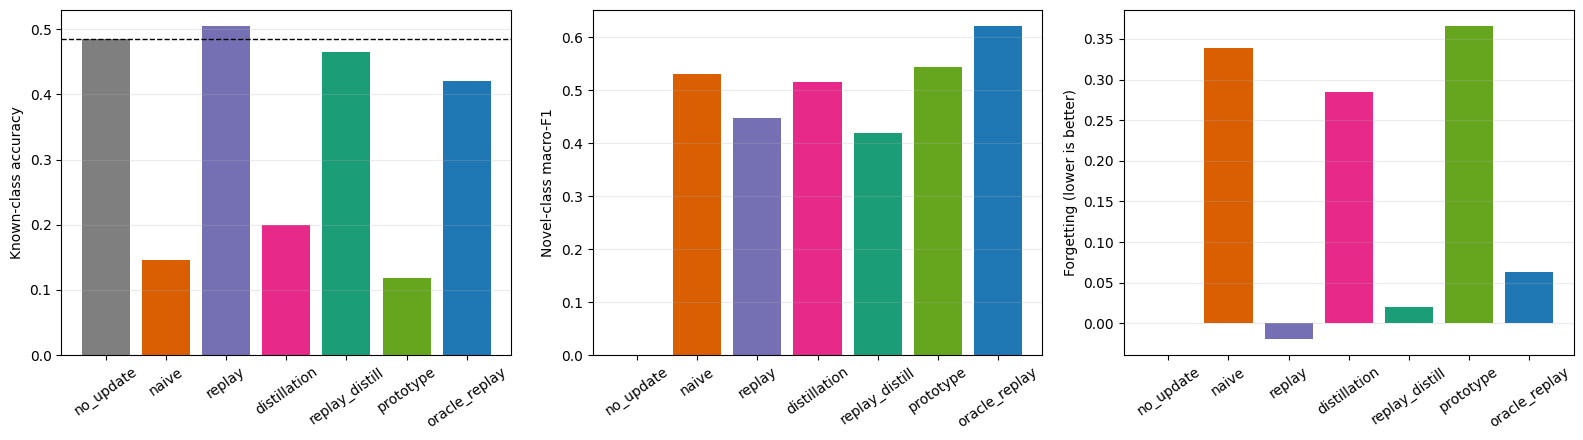

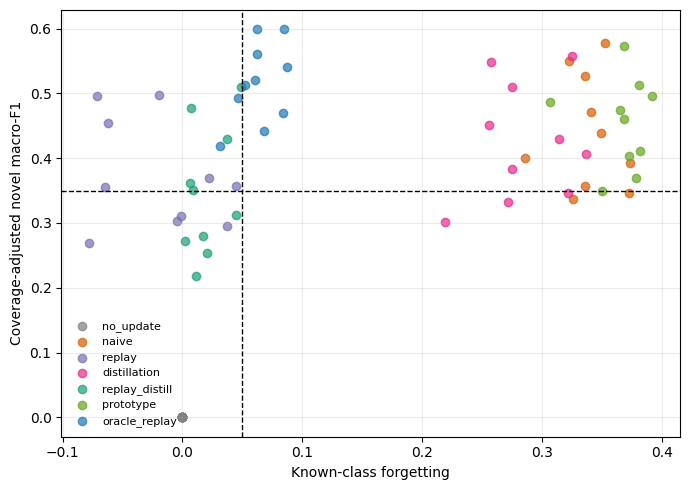

In [8]:
colors={'no_update':'#7f7f7f','naive':'#d95f02','replay':'#7570b3','distillation':'#e7298a',
        'replay_distill':'#1b9e77','prototype':'#66a61e','oracle_replay':'#1f78b4'}
agg=results.groupby('method',as_index=False).agg(
    known_accuracy=('known_accuracy','mean'),novel_f1=('novel_macro_f1','mean'),
    coverage_adjusted=('coverage_adjusted_novel_f1','mean'),forgetting=('forgetting','mean'),
    overall_f1=('overall_macro_f1','mean'))
order=list(METHODS);agg['order']=agg.method.map({m:i for i,m in enumerate(order)});agg=agg.sort_values('order')
fig,axes=plt.subplots(1,3,figsize=(16,4.5))
axes[0].bar(agg.method,agg.known_accuracy,color=[colors[x] for x in agg.method])
axes[1].bar(agg.method,agg.novel_f1,color=[colors[x] for x in agg.method])
axes[2].bar(agg.method,agg.forgetting,color=[colors[x] for x in agg.method])
axes[0].axhline(BASE_KNOWN_ACCURACY,color='black',ls='--',lw=1)
axes[0].set_ylabel('Known-class accuracy');axes[1].set_ylabel('Novel-class macro-F1')
axes[2].set_ylabel('Forgetting (lower is better)')
for ax in axes:ax.tick_params(axis='x',rotation=35);ax.grid(axis='y',alpha=.25)
fig.tight_layout();fig.savefig(OUT/'phase1b_method_comparison.png',dpi=180,bbox_inches='tight');plt.show()

fig,ax=plt.subplots(figsize=(7,5))
for method in METHODS:
    q=results[results.method==method]
    ax.scatter(q.forgetting,q.coverage_adjusted_novel_f1,label=method,color=colors[method],alpha=.7)
ax.axvline(CFG.max_known_accuracy_drop,color='black',ls='--',lw=1)
ax.axhline(CFG.minimum_coverage_adjusted_novel_f1,color='black',ls='--',lw=1)
ax.set_xlabel('Known-class forgetting');ax.set_ylabel('Coverage-adjusted novel macro-F1')
ax.grid(alpha=.25);ax.legend(frameon=False,fontsize=8);fig.tight_layout()
fig.savefig(OUT/'phase1b_stability_plasticity.png',dpi=180,bbox_inches='tight');plt.show()


## Decision gates

Replay plus distillation is the preregistered integration method. It must preserve the known vocabulary, learn the admitted novel vocabulary, and remain stable in both arrival modes. The oracle upper bound diagnoses data limitations but cannot satisfy a gate.


In [9]:
target=results[results.method=='replay_distill']
arrival=target.groupby('arrival_mode').agg(
    vocabulary_coverage=('vocabulary_coverage','mean'),known_accuracy=('known_accuracy','mean'),
    novel_macro_f1=('novel_macro_f1','mean'),coverage_adjusted_novel_f1=('coverage_adjusted_novel_f1','mean'),
    forgetting=('forgetting','mean'),overall_macro_f1=('overall_macro_f1','mean')).to_dict('index')
naive=results[results.method=='naive'].groupby('arrival_mode').agg(
    forgetting=('forgetting','mean'),novel_macro_f1=('novel_macro_f1','mean')).to_dict('index')

gates={
 'G1_disjoint_integration_and_evaluation_clients':not bool(set(CFG.integration_subjects)&set(CFG.evaluation_subjects)),
 'G2_dual_confirmation_only':bool((admissions.single_client_promotions==0).all()),
 'G3_vocabulary_coverage_each_arrival':bool(all(v['vocabulary_coverage']>=CFG.minimum_vocabulary_coverage for v in arrival.values())),
 'G4_known_accuracy_drop_each_arrival':bool(all(v['forgetting']<=CFG.max_known_accuracy_drop for v in arrival.values())),
 'G5_novel_macro_f1_each_arrival':bool(all(v['novel_macro_f1']>=CFG.minimum_novel_macro_f1 for v in arrival.values())),
 'G6_coverage_adjusted_novel_f1_each_arrival':bool(all(v['coverage_adjusted_novel_f1']>=CFG.minimum_coverage_adjusted_novel_f1 for v in arrival.values())),
 'G7_better_stability_than_naive':bool(all(arrival[m]['forgetting']<naive[m]['forgetting'] for m in CFG.arrival_modes)),
 'G8_auditability':bool(len(events)>0 and len(admissions)>0 and len(results)>0)
}
decision={'phase':'Phase 1B','base_known_accuracy':BASE_KNOWN_ACCURACY,'base_known_macro_f1':BASE_KNOWN_F1,
          'target_method':'replay_distill','arrival_results':arrival,'naive_results':naive,'gates':gates,
          'proceed_to_full_experiments':bool(all(gates.values())),
          'inheritance_enabled':False,
          'protocol':'Client-stratified direct confirmation; two distinct clients; disjoint evaluation clients.',
          'config':asdict(CFG)}
(OUT/'phase1b_decision.json').write_text(json.dumps(decision,indent=2))
print(json.dumps(decision,indent=2))


{
  "phase": "Phase 1B",
  "base_known_accuracy": 0.48484848484848486,
  "base_known_macro_f1": 0.461749455151776,
  "target_method": "replay_distill",
  "arrival_results": {
    "staggered": {
      "vocabulary_coverage": 0.8666666666666668,
      "known_accuracy": 0.46739393939393936,
      "novel_macro_f1": 0.43369748414405374,
      "coverage_adjusted_novel_f1": 0.37309762153936454,
      "forgetting": 0.017454545454545466,
      "overall_macro_f1": 0.38934613858422007
    },
    "synchronous": {
      "vocabulary_coverage": 0.8,
      "known_accuracy": 0.46157575757575753,
      "novel_macro_f1": 0.40570385551840393,
      "coverage_adjusted_novel_f1": 0.32033108013842965,
      "forgetting": 0.02327272727272729,
      "overall_macro_f1": 0.3711461816426815
    }
  },
  "naive_results": {
    "staggered": {
      "forgetting": 0.32751515151515154,
      "novel_macro_f1": 0.5463714692843187
    },
    "synchronous": {
      "forgetting": 0.3512727272727273,
      "novel_macro_f1": 

In [10]:
report=f"""# FedVocabHAR Phase 1B Decision Report

## Decision

**Proceed to full experiments:** {decision['proceed_to_full_experiments']}

**Integration method:** replay plus distillation

**Inheritance enabled:** False

## Base model

- Known-class accuracy: {BASE_KNOWN_ACCURACY:.4f}
- Known-class macro-F1: {BASE_KNOWN_F1:.4f}

## Arrival-specific results

{json.dumps(arrival,indent=2)}

## Gates

"""
for name,value in gates.items():report+=f'- {name}: **{value}**\n'
report+="""

Only directly confirmed fragments from integration clients were used for novel-class learning. Evaluation clients were held out from normalization, confirmation, training, replay, prototypes, and model selection.
"""
(OUT/'FedVocabHAR_Phase1B_Decision_Report.md').write_text(report)
print(report);print('saved outputs to',OUT)


# FedVocabHAR Phase 1B Decision Report

## Decision

**Proceed to full experiments:** False

**Integration method:** replay plus distillation

**Inheritance enabled:** False

## Base model

- Known-class accuracy: 0.4848
- Known-class macro-F1: 0.4617

## Arrival-specific results

{
  "staggered": {
    "vocabulary_coverage": 0.8666666666666668,
    "known_accuracy": 0.46739393939393936,
    "novel_macro_f1": 0.43369748414405374,
    "coverage_adjusted_novel_f1": 0.37309762153936454,
    "forgetting": 0.017454545454545466,
    "overall_macro_f1": 0.38934613858422007
  },
  "synchronous": {
    "vocabulary_coverage": 0.8,
    "known_accuracy": 0.46157575757575753,
    "novel_macro_f1": 0.40570385551840393,
    "coverage_adjusted_novel_f1": 0.32033108013842965,
    "forgetting": 0.02327272727272729,
    "overall_macro_f1": 0.3711461816426815
  }
}

## Gates

- G1_disjoint_integration_and_evaluation_clients: **True**
- G2_dual_confirmation_only: **True**
- G3_vocabulary_coverage_each_arri

## Interpretation

- If all gates pass, freeze the direct-only integration protocol and expand to multiple datasets and stronger federated continual-learning baselines.
- If vocabulary coverage fails, increase the confirmation budget or redesign client scheduling without using evaluation identities.
- If novel learning fails but the oracle upper bound succeeds, improve training from sparse confirmed fragments.
- If the oracle upper bound also fails, the fixed representation is inadequate for those activities.
- If forgetting fails, strengthen replay or freeze known-class weights before considering encoder adaptation.
